In [1]:
#EXERCISE 1
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage
from skimage.filters import gaussian
from skimage.restoration import denoise_nl_means, denoise_tv_chambolle
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

names = ["barbara", "fingerprint", "house"]
images = {}
for name in names:
    image = plt.imread(name + ".png")
    if image.ndim == 3:
        image = image[:, :, 0]
    images[name] = image

def add_noise(image, std):
    return image + np.random.normal(0, std, image.shape)

def box_filter(noisy):
    return ndimage.uniform_filter(noisy, size=3)               # mean box filter 3x3

def gaussian_filter(noisy, sigma=1, truncate=1):
    return gaussian(noisy, sigma=sigma, truncate=truncate)     # truncate=1 and sigma=1 give a 3x3 window

def median_filter(noisy):
    return ndimage.median_filter(noisy, size=3)                # median filter 3x3

def nlm_filter(noisy, std, h_factor=0.8):
    return denoise_nl_means(noisy, h=h_factor * std, sigma=std,
                            patch_size=5, patch_distance=6, fast_mode=True)

def tv_filter(noisy, weight=0.1):
    return denoise_tv_chambolle(noisy, weight=weight)

def psnr(image, result):
    return peak_signal_noise_ratio(image, result, data_range=1)

def ssim(image, result):
    return structural_similarity(image, result, data_range=1)

np.random.seed(0)
stds = [0.02, 0.05]
noisy = {}
for name in names:
    for std in stds:
        noisy[name, std] = add_noise(images[name], std)

for name in names:
    for std in stds:
        n = noisy[name, std]
        print(name, std, "noisy", round(psnr(images[name], n), 2),
              "box", round(psnr(images[name], box_filter(n)), 2),
              "gauss", round(psnr(images[name], gaussian_filter(n)), 2),
              "median", round(psnr(images[name], median_filter(n)), 2),
              "nlm", round(psnr(images[name], nlm_filter(n, std)), 2),
              "tv", round(psnr(images[name], tv_filter(n)), 2))


barbara 0.02 noisy 33.99 box 25.26 gauss 26.52 median 25.29 nlm 36.89 tv 25.32


barbara 0.05 noisy 26.02 box 24.93 gauss 26.03 median 24.66 nlm 32.21 tv 25.17


fingerprint 0.02 noisy 33.98 box 29.5 gauss 30.91 median 30.75 nlm 34.57 tv 25.02


fingerprint 0.05 noisy 26.01 box 28.66 gauss 29.67 median 28.43 nlm 29.6 tv 26.9
house 0.02 noisy 34.02 box 31.0 gauss 32.43 median 33.71 nlm 38.2 tv 31.0


house 0.05 noisy 26.0 box 29.86 gauss 30.75 median 30.6 nlm 34.2 tv 30.85


In [2]:
#EXERCISE 2
sigmas = [0.3, 0.4, 0.5, 0.6, 0.75, 1, 1.5, 2]
h_factors = [0.4, 0.5, 0.6, 0.8, 1.0, 1.2, 1.5]
weights = [0.002, 0.005, 0.01, 0.02, 0.03, 0.05, 0.08, 0.1, 0.15]

best = {}
for name in names:
    for std in stds:
        n = noisy[name, std]
        im = images[name]
        best[name, std, "gauss"] = max(
            ((psnr(im, gaussian_filter(n, s, 4)), s) for s in sigmas))
        best[name, std, "nlm"] = max(
            ((psnr(im, nlm_filter(n, std, h)), h) for h in h_factors))
        best[name, std, "tv"] = max(
            ((psnr(im, tv_filter(n, w)), w) for w in weights))

for name in names:
    for std in stds:
        print(name, std, "gauss sigma", best[name, std, "gauss"][1],
              "nlm h", best[name, std, "nlm"][1], "tv weight", best[name, std, "tv"][1])


barbara 0.02 gauss sigma 0.4 nlm h 1.0 tv weight 0.005
barbara 0.05 gauss sigma 0.5 nlm h 0.8 tv weight 0.02
fingerprint 0.02 gauss sigma 0.5 nlm h 1.2 tv weight 0.01
fingerprint 0.05 gauss sigma 0.6 nlm h 0.8 tv weight 0.03
house 0.02 gauss sigma 0.5 nlm h 0.6 tv weight 0.01
house 0.05 gauss sigma 0.75 nlm h 0.8 tv weight 0.03


image  std  method  PSNR  SSIM
barbara 0.02 noisy 33.99 0.894
barbara 0.02 box 25.26 0.79
barbara 0.02 gauss 34.51 0.915
barbara 0.02 median 25.29 0.8
barbara 0.02 nlm 36.9 0.954
barbara 0.02 tv 35.61 0.937
barbara 0.05 noisy 26.02 0.656
barbara 0.05 box 24.93 0.733
barbara 0.05 gauss 28.36 0.762
barbara 0.05 median 24.66 0.712


barbara 0.05 nlm 32.21 0.906
barbara 0.05 tv 29.47 0.825
fingerprint 0.02 noisy 33.98 0.983
fingerprint 0.02 box 29.5 0.954
fingerprint 0.02 gauss 35.27 0.988
fingerprint 0.02 median 30.75 0.962
fingerprint 0.02 nlm 34.95 0.985
fingerprint 0.02 tv 35.12 0.987
fingerprint 0.05 noisy 26.01 0.908
fingerprint 0.05 box 28.66 0.944


fingerprint 0.05 gauss 30.26 0.961
fingerprint 0.05 median 28.43 0.939
fingerprint 0.05 nlm 29.6 0.949
fingerprint 0.05 tv 29.19 0.95
house 0.02 noisy 34.02 0.833
house 0.02 box 31.0 0.863
house 0.02 gauss 36.01 0.904
house 0.02 median 33.71 0.863
house 0.02 nlm 38.26 0.943
house 0.02 tv 37.7 0.932
house 0.05 noisy 26.0 0.516
house 0.05 box 29.86 0.774
house 0.05 gauss 31.1 0.792
house 0.05 median 30.6 0.736
house 0.05 nlm 34.2 0.874
house 0.05 tv 32.88 0.845


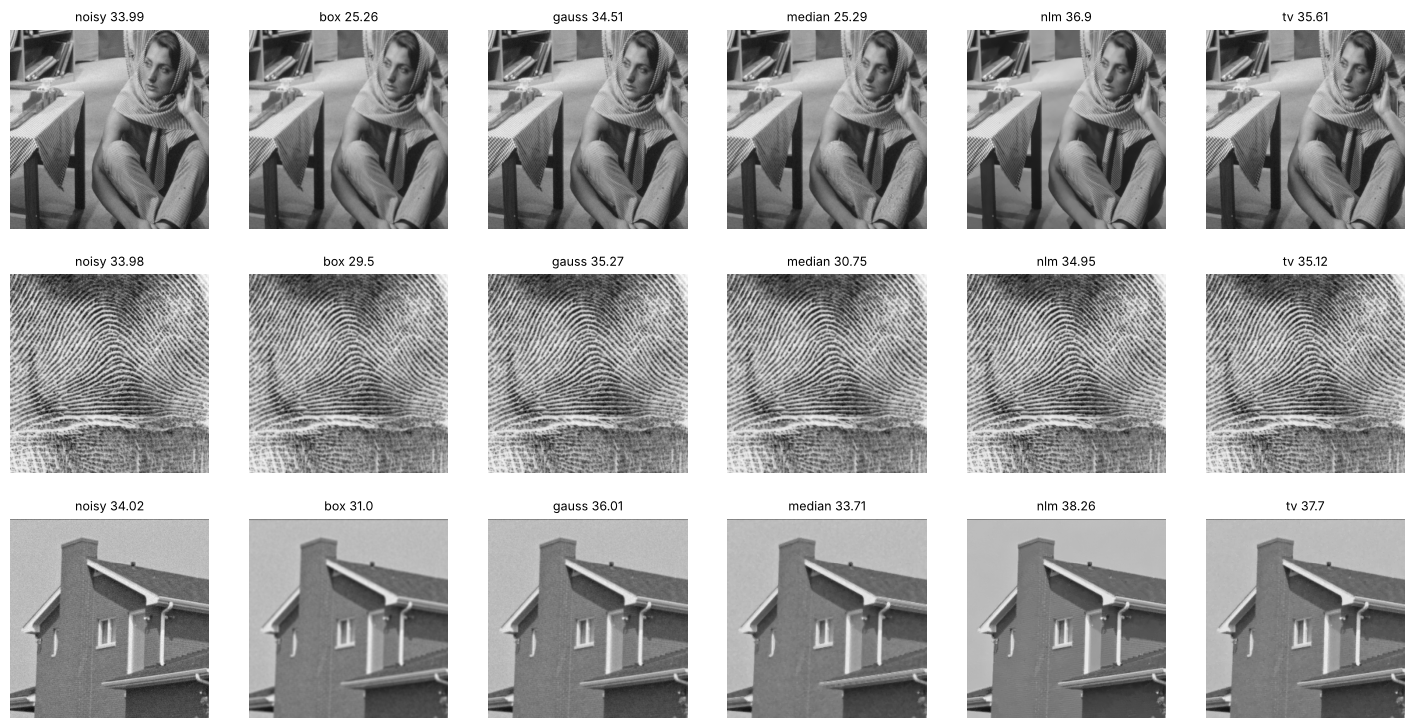

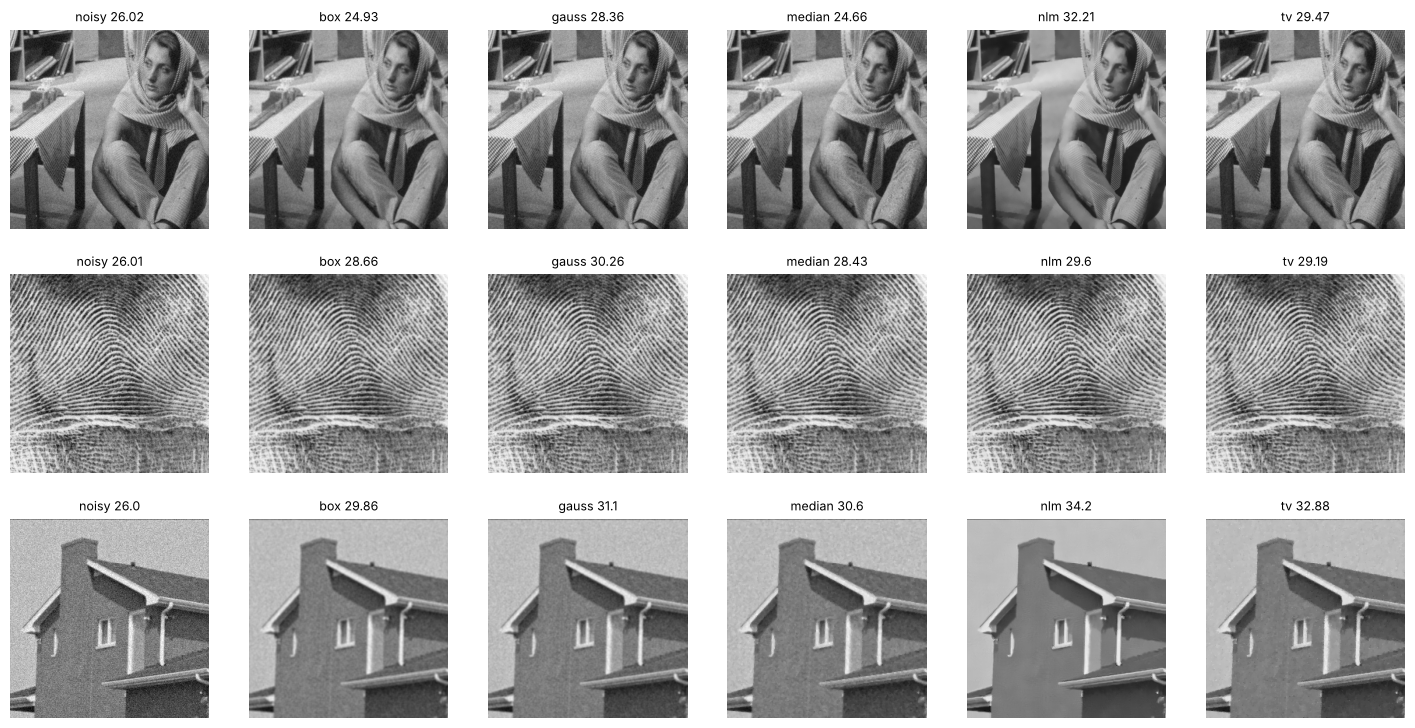

In [3]:
#EXERCISE 3
results = {}
for name in names:
    for std in stds:
        n = noisy[name, std]
        results[name, std] = {
            "noisy": n,
            "box": box_filter(n),
            "gauss": gaussian_filter(n, best[name, std, "gauss"][1], 4),
            "median": median_filter(n),
            "nlm": nlm_filter(n, std, best[name, std, "nlm"][1]),
            "tv": tv_filter(n, best[name, std, "tv"][1]),
        }

print("image  std  method  PSNR  SSIM")
for name in names:
    for std in stds:
        for method, res in results[name, std].items():
            print(name, std, method, round(psnr(images[name], res), 2), round(ssim(images[name], res), 3))

for std in stds:
    plt.figure(figsize=(18, 9))
    for i, name in enumerate(names):
        for j, (method, res) in enumerate(results[name, std].items()):
            plt.subplot(3, 6, i * 6 + j + 1)
            plt.imshow(res, cmap='gray', vmin=0, vmax=1)
            plt.title(method + " " + str(round(psnr(images[name], res), 2)), fontsize=9)
            plt.axis('off')
    plt.show()


#EXERCISE 4

Average over the 6 cases (3 images, 2 noise levels): PSNR / SSIM
- noisy 30.00 / 0.798
- box 28.20 / 0.843
- median 28.91 / 0.835
- gaussian 32.59 / 0.887
- TV 33.33 / 0.913
- NLM 34.35 / 0.935

Hierarchy: NLM > TV > Gaussian > median, box. SSIM gives the same order for the first three.

NLM is best for Barbara and House at both noise levels. For Fingerprint the Gaussian filter is the best at 0.05 and equal to TV and NLM at 0.02.
Box and median give a lower PSNR than the noisy image at std 0.02 and also on Barbara at std 0.05, they blur the edges and the textures.
The optimal Gaussian filter has a small sigma (0.4 to 0.75), it removes only a part of the noise.
Visually, NLM keeps the edges and the textures and cleans the flat areas. TV is close to NLM but less good. Gaussian leaves some noise. Box and median blur the image, the stripes of Barbara are lost.